# 05 · Stream mining (optional)

**DMDW topic:** mining data streams - one pass, incremental counters, sliding window, duplicate suppression. Replay mode feeds a finished contest's submissions in time order; `cfiq stream --live` polls the API instead.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from cfiq.config import load_config
from cfiq.db import get_engine, read_sql

cfg = load_config()
engine = get_engine()
REPORTS = cfg["paths"]["reports"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from cfiq.mining.stream import run_stream

In [2]:
stats, snaps = run_stream(cfg)
snaps.head(10)

,step,new,minute,processed,acceptance_rate,window_acceptance_rate,v_OK,v_WRONG_ANSWER,v_COMPILATION_ERROR,v_SKIPPED,v_IDLENESS_LIMIT_EXCEEDED,v_TIME_LIMIT_EXCEEDED
0,1,500,14,500,0.748000,0.748,374,109,6.0,4.0,2,0.0
1,2,500,26,1000,0.719000,0.690,719,225,12.0,12.0,21,0.0
2,3,500,41,1500,0.720667,0.724,1081,326,17.0,18.0,38,0.0
3,4,500,71,2000,0.729500,0.756,1459,407,21.0,27.0,51,0.0
4,5,500,114,2500,0.688400,0.524,1721,559,0.0,34.0,61,71.0
5,6,500,53,3000,0.659000,0.512,1977,726,40.0,0.0,64,113.0
6,7,500,35791394,3500,0.646571,0.572,2263,875,53.0,0.0,71,144.0
7,8,500,35791394,4000,0.629250,0.508,2517,1049,67.0,0.0,78,181.0
8,9,292,35791394,4292,0.623719,0.520,2677,1136,72.0,0.0,82,213.0


In [3]:
display(Markdown((REPORTS / 'stream' / 'summary.md').read_text()))

# Stream mining: contest 2287 (replay)

- Submissions processed: **4,292** in 9 batches/polls (each submission seen once; duplicates skipped by id)
- Final acceptance rate: **0.624**

| verdict | count |
|---|---|
| OK | 2677 |
| WRONG_ANSWER | 1136 |
| TIME_LIMIT_EXCEEDED | 213 |
| IDLENESS_LIMIT_EXCEEDED | 82 |
| COMPILATION_ERROR | 72 |
| RUNTIME_ERROR | 40 |
| SKIPPED | 37 |
| MEMORY_LIMIT_EXCEEDED | 30 |
| CHALLENGED | 5 |

| language_family | count |
|---|---|
| C++ | 4090 |
| Python | 113 |
| Java | 35 |
| Rust | 21 |
| C | 16 |
| Other | 7 |
| Kotlin | 5 |
| Go | 4 |
| C# | 1 |

![acceptance](contest_2287_acceptance.png)


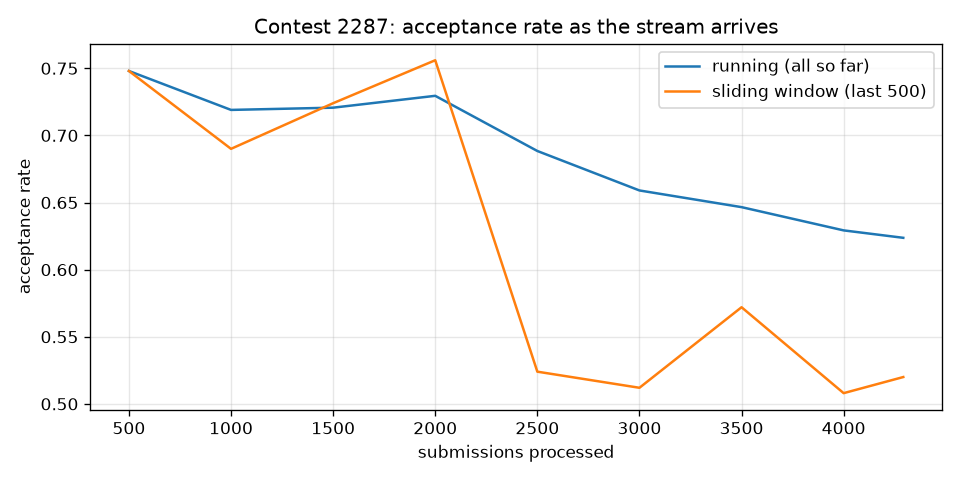

In [4]:
img = sorted((REPORTS / 'stream').glob('contest_*_acceptance.png'))[-1]
Image(img)